# Multimodal Embedding with EmbeddingGemma 2 and OpenVINO

[EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) is an open multimodal embedding model from Google DeepMind. It maps text, code, images, video, and audio into a single 768-dimensional vector space. The full model has 740M parameters: a 270M text backbone plus modular vision and audio encoders.

This notebook demonstrates the **full multimodal path** on OpenVINO:

- text embedding
- image embedding
- video embedding
- audio embedding
- interleaved text + image + audio + video embedding

The current OpenVINO converter cannot export the complete multimodal model as one IR, so this notebook exports the model as several OpenVINO IR parts: a text embedder, an image vision tower, a video vision tower, vision and audio embedders, and the language model. The notebook then merges the soft tokens in Python and runs the language model with OpenVINO.

Every OpenVINO embedding is compared with the original Sentence Transformers embedding, so the notebook is also an execution log for numerical validation.



### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/embeddinggemma-2/embeddinggemma-2.ipynb" />












#### Table of contents:

- [Prerequisites](#Prerequisites)
- [About EmbeddingGemma 2 multimodal inputs](#About-EmbeddingGemma-2-multimodal-inputs)
- [Create sample media](#Create-sample-media)
- [Load the processor and inspect multimodal features](#Load-the-processor-and-inspect-multimodal-features)
- [Convert model parts to OpenVINO IR](#Convert-model-parts-to-OpenVINO-IR)
- [Select inference device](#Select-inference-device)
- [Compile the exported OpenVINO parts](#Compile-the-exported-OpenVINO-parts)
- [Design logic and consistency with Transformers](#Design-logic-and-consistency-with-Transformers)
    - [Scope and limitations](#Scope-and-limitations)
- [Run OpenVINO multimodal inference](#Run-OpenVINO-multimodal-inference)
- [Compare with the original Sentence Transformers model](#Compare-with-the-original-Sentence-Transformers-model)
- [Benchmark inference speed](#Benchmark-inference-speed)
- [Measured NPU result](#Measured-NPU-result)
- [Matryoshka dimension truncation](#Matryoshka-dimension-truncation)
- [Clean up](#Clean-up)




## Prerequisites
[back to top ⬆️](#Table-of-contents:)

In [1]:
%pip install -q "openvino>=2026.4.1" "openvino-tokenizers>=2026.4.1" "transformers==5.19.0" "sentence-transformers==6.1.0" "torch==2.14.1" "torchvision==0.29.1" "av" "soundfile" "Pillow" "requests" "ipywidgets"

In [2]:
from pathlib import Path

import requests

if not Path("cmd_helper.py").exists():
    r = requests.get(url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/cmd_helper.py")
    open("cmd_helper.py", "w").write(r.text)

if not Path("notebook_utils.py").exists():
    r = requests.get(url="https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/notebook_utils.py")
    open("notebook_utils.py", "w").write(r.text)

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("embeddinggemma-2.ipynb")


## About EmbeddingGemma 2 multimodal inputs
[back to top ⬆️](#Table-of-contents:)

EmbeddingGemma 2 uses placeholder tokens in the text sequence to mark where image, video, and audio soft tokens are inserted:

| Modality | Placeholder | Processor input |
|---|---|---|
| Image | `<\|image\|>` | `images` |
| Video | `<\|video\|>` | `videos` |
| Audio | `<\|audio\|>` | `audio` |

A single input can mix all modalities. This notebook uses one small synthetic sample per modality so the full pipeline runs quickly on CPU.

In [3]:
MODEL_ID = "google/embeddinggemma-2"
MODEL_REVISION = "914f7f89142e33e77833254d9c9b90c3cef7303b"

QUERY_PREFIX = "task: search result | query: "
DOCUMENT_PREFIX = "title: none | text: "

IR_DIR = Path("openvino-ir")


## Create sample media
[back to top ⬆️](#Table-of-contents:)

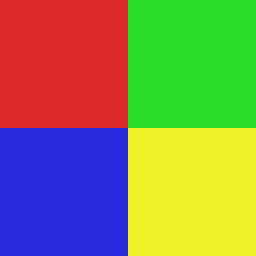

In [4]:
import numpy as np
from PIL import Image

image = Image.new("RGB", (256, 256), (0, 0, 0))
pixels = image.load()
for y in range(256):
    for x in range(256):
        if x < 128 and y < 128:
            pixels[x, y] = (220, 40, 40)
        elif x >= 128 and y < 128:
            pixels[x, y] = (40, 220, 40)
        elif x < 128:
            pixels[x, y] = (40, 40, 220)
        else:
            pixels[x, y] = (240, 240, 40)

sample_rate = 16000
time = np.linspace(0, 3.0, int(sample_rate * 3.0), endpoint=False)
waveform = (0.4 * np.sin(2 * np.pi * 440 * time) + 0.2 * np.sin(2 * np.pi * 880 * time)).astype(np.float32)

video_frames = []
for frame_idx in range(3):
    frame = Image.new("RGB", (96, 96), (0, 0, 0))
    frame_pixels = frame.load()
    for y in range(96):
        for x in range(96):
            if (x // 12 + y // 12 + frame_idx) % 2 == 0:
                frame_pixels[x, y] = (220, 40 + frame_idx * 60, 40)
            else:
                frame_pixels[x, y] = (240, 240, 40)
    video_frames.append(frame)

image


## Load the processor and inspect multimodal features
[back to top ⬆️](#Table-of-contents:)

In [5]:
import torch
from transformers import AutoProcessor

processor = AutoProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)

print("image token:", processor.image_token, processor.image_token_id)
print("video token:", processor.video_token, processor.video_token_id)
print("audio token:", processor.audio_token, processor.audio_token_id)

cases = {
    "text": {"text": [QUERY_PREFIX + "a red and green square"]},
    "image": {"text": ["<|image|>"], "images": [[image]]},
    "video": {"text": ["<|video|>"], "videos": [video_frames]},
    "audio": {"text": ["<|audio|>"], "audio": [waveform]},
    "interleaved": {
        "text": ["chart: <|image|> sound: <|audio|> motion: <|video|>"],
        "images": [[image]],
        "audio": [waveform],
        "videos": [video_frames],
    },
}

features_by_case = {name: processor(return_tensors="pt", **kwargs) for name, kwargs in cases.items()}

for name, features in features_by_case.items():
    print(f"\n{name}")
    for key, value in features.items():
        if isinstance(value, torch.Tensor):
            print(" ", key, tuple(value.shape), value.dtype)


[transformers] Asked to sample uniformly with `fps`, but the video metadata has no `fps` or `duration`. Keeping every frame and applying only the `max_frames` budget. Pass a `VideoMetadata` object with a valid `fps` and `duration` to sample at a target frame rate.


image token: <|image|> 258880
video token: <|video|> 258884
audio token: <|audio|> 258881



text
  input_ids (1, 14) torch.int64
  attention_mask (1, 14) torch.int64

image
  input_ids (1, 260) torch.int64
  attention_mask (1, 260) torch.int64
  pixel_values (1, 2520, 768) torch.float32
  image_position_ids (1, 2520, 2) torch.int64

video
  input_ids (1, 371) torch.int64
  attention_mask (1, 371) torch.int64
  pixel_values_videos (3, 1260, 768) torch.float32
  video_position_ids (3, 1260, 2) torch.int64
  num_frames_per_video (1,) torch.int64

audio
  input_ids (1, 79) torch.int64
  attention_mask (1, 79) torch.int64
  input_features (1, 299, 128) torch.float32
  input_features_mask (1, 299) torch.bool

interleaved
  input_ids (1, 715) torch.int64
  attention_mask (1, 715) torch.int64
  pixel_values (1, 2520, 768) torch.float32
  image_position_ids (1, 2520, 2) torch.int64
  pixel_values_videos (3, 1260, 768) torch.float32
  video_position_ids (3, 1260, 2) torch.int64
  num_frames_per_video (1,) torch.int64
  input_features (1, 299, 128) torch.float32
  input_features_mask (

## Convert model parts to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

The full `EmbeddingGemma2Model` is not exported as one IR because the current OpenVINO PyTorch frontend cannot handle the data-dependent video split in `get_video_features`. The parts below are exported separately and composed at inference time.

The text embedder, vision tower, audio tower, and language model are exported with `torch.export` through OpenVINO. Dynamic dimensions are requested where the frontend supports them; the vision tower is exported twice because image and video batch axes differ in this pipeline.

In [6]:
import openvino as ov
from transformers import AutoModel

IR_DIR.mkdir(parents=True, exist_ok=True)
model = AutoModel.from_pretrained(MODEL_ID, revision=MODEL_REVISION, dtype=torch.float32, attn_implementation="sdpa")
model.eval()

interleaved = features_by_case["interleaved"]

with torch.no_grad():
    image_mask, video_mask, audio_mask = model.get_placeholder_mask(interleaved["input_ids"])
    multimodal_mask = image_mask | video_mask | audio_mask
    llm_input_ids = torch.where(multimodal_mask, model.config.text_config.pad_token_id, interleaved["input_ids"])
    text_embeds_example = model.get_input_embeddings()(llm_input_ids)

    vision_out_example = model.vision_tower(
        pixel_values=interleaved["pixel_values"],
        pixel_position_ids=interleaved["image_position_ids"],
    ).last_hidden_state
    vision_embed_example = model.embed_vision(inputs_embeds=vision_out_example)

    video_vision_out_example = model.vision_tower(
        pixel_values=interleaved["pixel_values_videos"],
        pixel_position_ids=interleaved["video_position_ids"],
    ).last_hidden_state

    audio_out_example = model.audio_tower(
        input_features=interleaved["input_features"],
        input_features_mask=interleaved["input_features_mask"],
    ).last_hidden_state

    merged_embeds_example = text_embeds_example.clone()
    image_features_example = torch.cat(
        model.get_image_features(interleaved["pixel_values"], interleaved["image_position_ids"]).pooler_output,
        dim=0,
    )
    image_mask_expanded = image_mask.unsqueeze(-1).expand_as(merged_embeds_example)
    merged_embeds_example = merged_embeds_example.masked_scatter(image_mask_expanded, image_features_example.to(merged_embeds_example.dtype))

    video_features_example = torch.cat(
        model.get_video_features(
            interleaved["pixel_values_videos"],
            interleaved["video_position_ids"],
            interleaved["num_frames_per_video"],
        ).pooler_output,
        dim=0,
    )
    video_mask_expanded = video_mask.unsqueeze(-1).expand_as(merged_embeds_example)
    merged_embeds_example = merged_embeds_example.masked_scatter(video_mask_expanded, video_features_example.to(merged_embeds_example.dtype))

    audio_output_example = model.get_audio_features(interleaved["input_features"], interleaved["input_features_mask"])
    audio_features_example = audio_output_example.pooler_output[audio_output_example.attention_mask.to(audio_output_example.pooler_output.device)]
    audio_mask_expanded = audio_mask.unsqueeze(-1).expand_as(merged_embeds_example)
    merged_embeds_example = merged_embeds_example.masked_scatter(audio_mask_expanded, audio_features_example.to(merged_embeds_example.dtype))

PAD_TOKEN_ID = model.config.text_config.pad_token_id


def export_openvino_model(module: torch.nn.Module, example_input: dict, input_spec: dict, name: str) -> None:
    """Export one PyTorch module to OpenVINO IR.

    :param module: PyTorch module to export.
    :param example_input: Representative input tensors for tracing.
    :param input_spec: OpenVINO input names, shapes, and element types.
    :param name: Output IR file stem.
    """
    ov_model = ov.convert_model(module, example_input=example_input, input=input_spec, dynamo=True)
    ov.save_model(ov_model, IR_DIR / f"{name}.xml")
    print("exported", name)


export_openvino_model(
    model.get_input_embeddings(),
    {"input_ids": llm_input_ids},
    {"input_ids": (ov.PartialShape([-1, -1]), ov.Type.i64)},
    "text-embedder",
)
export_openvino_model(
    model.vision_tower,
    {"pixel_values": interleaved["pixel_values"], "pixel_position_ids": interleaved["image_position_ids"]},
    {
        "pixel_values": (ov.PartialShape([1, -1, 768]), ov.Type.f32),
        "pixel_position_ids": (ov.PartialShape([1, -1, 2]), ov.Type.i64),
    },
    "vision-tower-image",
)
export_openvino_model(
    model.vision_tower,
    {"pixel_values": interleaved["pixel_values_videos"], "pixel_position_ids": interleaved["video_position_ids"]},
    {
        "pixel_values": (ov.PartialShape([3, -1, 768]), ov.Type.f32),
        "pixel_position_ids": (ov.PartialShape([3, -1, 2]), ov.Type.i64),
    },
    "vision-tower-video",
)
export_openvino_model(
    model.embed_vision,
    {"inputs_embeds": vision_out_example},
    {"inputs_embeds": (ov.PartialShape([-1, 768]), ov.Type.f32)},
    "vision-embedder",
)
export_openvino_model(
    model.audio_tower,
    {"input_features": interleaved["input_features"], "input_features_mask": interleaved["input_features_mask"]},
    {
        "input_features": (ov.PartialShape([-1, -1, 128]), ov.Type.f32),
        "input_features_mask": (ov.PartialShape([-1, -1]), ov.Type.i8),
    },
    "audio-tower",
)
export_openvino_model(
    model.embed_audio,
    {"inputs_embeds": audio_out_example},
    {"inputs_embeds": (ov.PartialShape([-1, -1, 1536]), ov.Type.f32)},
    "audio-embedder",
)
export_openvino_model(
    model.language_model,
    {"inputs_embeds": merged_embeds_example, "attention_mask": interleaved["attention_mask"]},
    {
        "inputs_embeds": (ov.PartialShape([-1, -1, 512]), ov.Type.f32),
        "attention_mask": (ov.PartialShape([-1, -1]), ov.Type.i64),
    },
    "language-model",
)

del model
import gc

gc.collect()


Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

W1027 21:22:55.108000 139592 Lib\site-packages\torch\_export\non_strict_utils.py:825] dimension inputs['input_ids'].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.


exported text-embedder


exported vision-tower-image


exported vision-tower-video


...

exported audio-embedder


W1027 21:24:36.495000 139592 Lib\site-packages\torch\_export\non_strict_utils.py:825] dimension inputs['inputs_embeds'].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.


W1027 21:24:36.498000 139592 Lib\site-packages\torch\_export\non_strict_utils.py:825] dimension inputs['attention_mask'].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.


exported language-model


122281

## Select inference device
[back to top ⬆️](#Table-of-contents:)

`NPU` is listed when the OpenVINO NPU plugin and driver are installed. The multimodal parts are exported with dynamic axes, so if NPU compilation fails on your driver, select `CPU` or `GPU`.

In [7]:
from notebook_utils import device_widget

device = device_widget(default="CPU", exclude=[])

device


Dropdown(description='Device:', options=('CPU', 'GPU', 'AUTO'), value='CPU')

## Compile the exported OpenVINO parts
[back to top ⬆️](#Table-of-contents:)

The IR parts are compiled after the device is selected.

In [8]:
core = ov.Core()


def compile_openvino_part(name: str) -> ov.CompiledModel:
    """Read one exported OpenVINO IR part and compile it for the selected device.

    :param name: IR file stem.
    :return: Compiled OpenVINO model.
    """
    model = core.read_model(IR_DIR / f"{name}.xml")
    print("compiled", name, "for", device.value)
    return core.compile_model(model, device.value)


text_embedder = compile_openvino_part("text-embedder")
vision_tower_image = compile_openvino_part("vision-tower-image")
vision_tower_video = compile_openvino_part("vision-tower-video")
vision_embedder = compile_openvino_part("vision-embedder")
audio_tower = compile_openvino_part("audio-tower")
audio_embedder = compile_openvino_part("audio-embedder")
language_model = compile_openvino_part("language-model")


compiled text-embedder for CPU
compiled vision-tower-image for CPU


compiled vision-tower-video for CPU


compiled vision-embedder for CPU


compiled audio-tower for CPU


compiled audio-embedder for CPU


compiled language-model for CPU


## Design logic and consistency with Transformers
[back to top ⬆️](#Table-of-contents:)

The current OpenVINO converter cannot export the complete multimodal model as one IR, so this notebook exports the model parts separately and composes them in Python. The composition is not a reimplementation of the neural layers: each image tower, video tower, audio tower, embedder, and the language model is executed from its exported OpenVINO IR.

The Python composition mirrors `EmbeddingGemma2Model.forward` in Transformers v5.19.0:

1. Build image, video, and audio placeholder masks from the placeholder token ids.
2. Replace multimodal placeholder positions with `pad_token_id`.
3. Embed the hard text tokens with the text embedder.
4. Merge soft tokens in the same order as Transformers: image, then video, then audio.
5. Run the language model with the merged `inputs_embeds` and the original `attention_mask`.
6. Mean-pool with the attention mask and L2-normalize, matching the Sentence Transformers pooling path.

The PyTorch reference model uses SDPA attention. Using eager attention instead changes the audio embedding enough to drop audio cosine to about `0.99`, while SDPA keeps all modalities at cosine `1.0` in the committed run.

### Scope and limitations
[back to top ⬆️](#Table-of-contents:)

This notebook demonstrates the composition with small synthetic samples and batch size `1`. It does not pass custom `position_ids`, derives the number of valid audio tokens from the placeholder mask, and assumes the processor's single-video layout for the sample video. Arbitrary batching, custom position ids, and more complex audio or video padding layouts would need a more general merge implementation.

## Run OpenVINO multimodal inference
[back to top ⬆️](#Table-of-contents:)

The inference pipeline mirrors the PyTorch model:

1. Embed hard text tokens with the text embedder.
2. Replace image, video, and audio placeholder positions with OpenVINO encoder features.
3. Run the language model on the merged embeddings.
4. Mean-pool with the attention mask and L2-normalize.

In [9]:
def run_openvino_model(compiled_model: ov.CompiledModel, feeds: dict) -> np.ndarray:
    """Run one compiled OpenVINO model and return its first output as a NumPy array."""
    request = compiled_model.create_infer_request()
    for port in compiled_model.inputs:
        name = port.any_name
        if name == "pixel_position_ids":
            name = "image_position_ids"
        request.set_tensor(port, ov.Tensor(np.ascontiguousarray(feeds[name])))
    request.infer()
    outputs = [request.get_tensor(port).data for port in compiled_model.outputs]
    return outputs[0] if len(outputs) == 1 else outputs


def assign_placeholder_features(inputs_embeds: np.ndarray, mask: np.ndarray, features: np.ndarray) -> None:
    """Write encoder features into placeholder positions in batch order."""
    offset = 0
    for batch_index in range(mask.shape[0]):
        positions = np.flatnonzero(mask[batch_index])
        count = len(positions)
        inputs_embeds[batch_index, positions] = features[offset : offset + count]
        offset += count
    if offset != len(features):
        raise ValueError(f"Feature count mismatch: assigned {offset}, received {len(features)}")


def openvino_embed(features: dict) -> np.ndarray:
    """Encode one processor output with the exported OpenVINO model parts."""
    input_ids = features["input_ids"].numpy().astype(np.int64)
    attention_mask = features["attention_mask"].numpy().astype(np.int64)

    image_mask = input_ids == processor.image_token_id
    video_mask = input_ids == processor.video_token_id
    audio_mask = input_ids == processor.audio_token_id
    multimodal_mask = image_mask | video_mask | audio_mask
    llm_input_ids = np.where(multimodal_mask, PAD_TOKEN_ID, input_ids)

    inputs_embeds = run_openvino_model(text_embedder, {"input_ids": llm_input_ids}).copy()

    if "pixel_values" in features:
        vision_out = run_openvino_model(
            vision_tower_image,
            {
                "pixel_values": features["pixel_values"].numpy(),
                "image_position_ids": features["image_position_ids"].numpy(),
            },
        )
        image_features = run_openvino_model(vision_embedder, {"inputs_embeds": vision_out})
        assign_placeholder_features(inputs_embeds, image_mask, image_features)

    if "pixel_values_videos" in features:
        video_vision_out = run_openvino_model(
            vision_tower_video,
            {
                "pixel_values": features["pixel_values_videos"].numpy(),
                "image_position_ids": features["video_position_ids"].numpy(),
            },
        )
        video_features = run_openvino_model(vision_embedder, {"inputs_embeds": video_vision_out})
        assign_placeholder_features(inputs_embeds, video_mask, video_features)

    if "input_features" in features:
        audio_out = run_openvino_model(
            audio_tower,
            {
                "input_features": features["input_features"].numpy(),
                "input_features_mask": features["input_features_mask"].numpy().astype(np.int8),
            },
        )
        audio_projected = run_openvino_model(audio_embedder, {"inputs_embeds": audio_out})
        valid_audio_tokens = int(audio_mask.sum())
        audio_features = audio_projected[0, :valid_audio_tokens]
        assign_placeholder_features(inputs_embeds, audio_mask, audio_features)

    last_hidden_state = run_openvino_model(
        language_model,
        {"inputs_embeds": inputs_embeds, "attention_mask": attention_mask},
    )[0]
    mask = attention_mask[0].astype(np.float32)[:, None]
    pooled = (last_hidden_state * mask).sum(axis=0) / mask.sum(axis=0)
    return pooled / np.linalg.norm(pooled)


openvino_embeddings = {name: openvino_embed(features) for name, features in features_by_case.items()}

for name, embedding in openvino_embeddings.items():
    print(name, "shape=", embedding.shape, "norm=", float(np.linalg.norm(embedding)))


text shape= (768,) norm= 0.9999998807907104
image shape= (768,) norm= 1.0
video shape= (768,) norm= 1.0
audio shape= (768,) norm= 1.0
interleaved shape= (768,) norm= 1.0


## Compare with the original Sentence Transformers model
[back to top ⬆️](#Table-of-contents:)

In [10]:
from sentence_transformers import SentenceTransformer

reference_model = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, model_kwargs={"dtype": torch.float32})
reference_model.max_seq_len = 512

reference_inputs = {
    "text": QUERY_PREFIX + "a red and green square",
    "image": {"text": "<|image|>", "image": image},
    "video": {"text": "<|video|>", "video": video_frames},
    "audio": {"text": "<|audio|>", "audio": waveform},
    "interleaved": {
        "text": "chart: <|image|> sound: <|audio|> motion: <|video|>",
        "image": image,
        "audio": waveform,
        "video": video_frames,
    },
}

for name, payload in reference_inputs.items():
    reference = reference_model.encode(payload, normalize_embeddings=True)
    openvino_embedding = openvino_embeddings[name]
    cosine = float(np.dot(reference, openvino_embedding))
    max_abs_diff = float(np.max(np.abs(reference - openvino_embedding)))
    print(f"{name}: cosine={cosine:.9f}, max_abs_diff={max_abs_diff:.3e}")


Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

text: cosine=1.000000000, max_abs_diff=2.746e-06


image: cosine=1.000000000, max_abs_diff=4.794e-05


video: cosine=0.999999940, max_abs_diff=6.614e-05


audio: cosine=1.000000000, max_abs_diff=3.024e-05


interleaved: cosine=0.999999821, max_abs_diff=9.365e-05


## Benchmark inference speed
[back to top ⬆️](#Table-of-contents:)

This benchmark compares the OpenVINO IR pipeline on the selected device with the original Sentence Transformers model on CPU. If you select `NPU`, the comparison becomes NPU inference versus the non-NPU PyTorch CPU reference, so the same cell can show the value of NPU acceleration on a machine where NPU compilation succeeds.

A measured NPU result is recorded in [Measured NPU result](#Measured-NPU-result).

In [11]:
import time

BENCH_RUNS = 3


def benchmark_ms(fn, runs: int = BENCH_RUNS) -> float:
    """Run `fn` once as warmup, then return the average latency in milliseconds."""
    fn()
    start = time.perf_counter()
    for _ in range(runs):
        fn()
    return (time.perf_counter() - start) * 1000 / runs


print(f"OpenVINO device: {device.value}")
print("PyTorch reference device: cpu")
print()
print(f"{'modality':<12}{'openvino_ms':>14}{'pytorch_cpu_ms':>18}{'speedup':>10}")
for name, payload in reference_inputs.items():
    openvino_ms = benchmark_ms(lambda name=name: openvino_embed(features_by_case[name]))
    pytorch_ms = benchmark_ms(lambda payload=payload: reference_model.encode(payload, normalize_embeddings=True))
    print(f"{name:<12}{openvino_ms:>14.1f}{pytorch_ms:>18.1f}{pytorch_ms / openvino_ms:>9.2f}x")


OpenVINO device: CPU
PyTorch reference device: cpu

modality       openvino_ms    pytorch_cpu_ms   speedup


text                  65.1             126.2     1.94x


image               6854.3            8045.5     1.17x


video               6551.4            8090.5     1.23x


audio                374.7             706.0     1.88x


interleaved        10867.8           13199.3     1.21x


## Measured NPU result
[back to top ⬆️](#Table-of-contents:)

The table below is a measured run on an Intel Core Ultra 7 155H laptop with the Intel NPU driver `32.0.100.5540` and OpenVINO `2026.4.1`. It compares the static-shape NPU pipeline with the dynamic-shape OpenVINO CPU pipeline for the same synthetic samples, batch size `1`, three runs after one warmup run. NPU compilation time is not included in the inference latency.

| modality | input tokens | OpenVINO CPU ms | NPU ms | NPU speedup | cosine vs CPU | max abs diff |
|---|---:|---:|---:|---:|---:|---:|
| text | 14 | 80.7 | 477.2 | 0.17x | 1.000000 | 0.000111 |
| long_text | 715 | 2870.3 | 477.2 | 6.02x | 0.999933 | 0.001295 |
| audio | 79 | 616.1 | 520.0 | 1.18x | 0.992069 | 0.015026 |

The NPU latency is almost flat for `text` and `long_text` because the NPU graph is static at `715` tokens. The CPU pipeline is dynamic, so it scales with the real input length. That is why short text looks bad on NPU and long text looks good: the same static NPU graph that wastes work on a 14-token query becomes a `6.02x` win when the input really is `715` tokens.

References for this behavior:

- OpenVINO NPU currently requires static shapes: [NPU Device](https://docs.openvino.ai/2024/openvino-workflow/running-inference/inference-devices-and-modes/npu-device.html) and [Understanding NPUs with OpenVINO](https://huggingface.co/blog/Neural-Hacker/openvino).
- `optimum-cli` does not expose static input shapes for Sentence Transformers export, see [optimum-intel issue #1581](https://github.com/huggingface/optimum-intel/issues/1581); this notebook therefore reshapes the exported IR itself.
- Use `benchmark_app` with `-d NPU` to inspect fallback messages and partial NPU execution when profiling a new model.
- `notebooks/hello-npu/hello-npu.ipynb` shows how to query NPU device properties in OpenVINO.

Read this as a capability and offload result, not a universal speedup. On this driver and model size, NPU audio offload is faster than CPU for the tested sample, and NPU text inference wins once the input is long enough to amortize the static `715`-token graph. The image and video vision towers are not included in the measured NPU table: the tested NPU driver returned an incorrect output shape for the exported vision tower, so the image and video NPU path still needs a plugin-side fix or a CPU/GPU fallback for those towers.

## Matryoshka dimension truncation
[back to top ⬆️](#Table-of-contents:)

In [12]:
TRUNCATION_DIM = 256


def truncate_embedding(embedding: np.ndarray, dim: int) -> np.ndarray:
    """Truncate an embedding to `dim` and re-normalize it."""
    truncated = embedding[:dim]
    return truncated / np.linalg.norm(truncated)


for name in ["text", "image", "interleaved"]:
    truncated = truncate_embedding(openvino_embeddings[name], TRUNCATION_DIM)
    print(name, "truncated shape=", truncated.shape, "norm=", float(np.linalg.norm(truncated)))


text truncated shape= (256,) norm= 0.9999999403953552
image truncated shape= (256,) norm= 1.0
interleaved truncated shape= (256,) norm= 1.0


## Clean up
[back to top ⬆️](#Table-of-contents:)

In [13]:
# import shutil
# shutil.rmtree(IR_DIR, ignore_errors=True)
